# **TEST REPORT – BACKEND DSP & MACHINE LEARNING**

# ***ADPIS PROJECT***

## 1. Mục tiêu kiểm thử:
Thực hiện kiểm thử toàn bộ hệ thống Backend bao gồm các thành phần:

* Tải và xử lý file âm thanh (Audio I/O)
* Equalizer dựa trên FFT
* So sánh tín hiệu trước và sau khi áp dụng EQ
* Đo mức gain thực tế của từng dải tần
* Phát hiện clipping
* Đo năng lượng RMS
* So sánh dạng sóng (Waveform)
* So sánh phổ tần (Spectrum)
* Kiểm thử mô hình Machine Learning (Phân loại thể loại nhạc)
* Tổng hợp đánh giá PASS / FAIL

## Mục tiêu chính
Xác minh rằng hệ thống Equalizer xử lý tín hiệu chính xác theo cấu hình đã thiết lập, đồng thời đảm bảo:

* Không gây méo tín hiệu (clipping, distortion)
* Không làm thay đổi năng lượng bất thường
* Thay đổi phổ tần đúng theo các dải tần cấu hình
* Mô hình Machine Learning hoạt động chính xác và trả về kết quả hợp lệ

## 2. Test Cases và import thư viện:

| Mã TC | Module           | Mục tiêu kiểm thử                                        | Hàm Backend sử dụng                   | Phương pháp kiểm tra                                               | Kết quả mong đợi                                       | Tiêu chí PASS                                           |
| ----- | ---------------- | -------------------------------------------------------- | ------------------------------------- | ------------------------------------------------------------------ | ------------------------------------------------------ | ------------------------------------------------------- |
| TC01  | Audio I/O        | Kiểm tra file âm thanh được tải đúng từ thư mục dataset. | `audio.audio_io.load_audio()`         | Kiểm tra sự tồn tại file, độ dài tín hiệu, sample rate và biên độ. | Tín hiệu hợp lệ, sample rate đúng, không lỗi khi load. | Không có lỗi runtime và độ dài tín hiệu > 0             |
| TC02  | Equalizer Gain   | Xác minh gain của từng dải tần khớp với cấu hình.        | `audio.pipeline.equalizer_pipeline()` | So sánh năng lượng FFT từng band trước và sau xử lý.               | Gain đo được gần với gain cấu hình.                    | Sai số ≤ ±1 dB cho mỗi band                             |
| TC03  | Clipping         | Đảm bảo tín hiệu sau EQ không vượt quá ngưỡng chuẩn hóa. | `audio.pipeline.equalizer_pipeline()` | Tính biên độ đỉnh tuyệt đối sau xử lý.                             | Biên độ đỉnh ≤ 1.0                                     | Không vượt quá ±1 (không clipping)                      |
| TC04  | RMS              | Đánh giá sự thay đổi năng lượng RMS sau EQ.              | `audio.pipeline.equalizer_pipeline()` | So sánh RMS trước và sau xử lý.                                    | RMS thay đổi hợp lý theo cấu hình gain.                | Không có khuếch đại bất thường hoặc suy giảm quá mức    |
| TC05  | Waveform         | Xác nhận dạng sóng thay đổi sau khi áp dụng EQ.          | `audio.pipeline.equalizer_pipeline()` | Chồng hai waveform và tính tín hiệu sai khác.                      | Có sự khác biệt rõ ràng giữa hai tín hiệu.             | Waveform sau xử lý khác waveform ban đầu                |
| TC06  | Spectrum         | Kiểm tra phổ tần thay đổi đúng theo dải tần đã chọn.     | `audio.pipeline.equalizer_pipeline()` | So sánh biên độ phổ FFT trước và sau xử lý.                        | Các band được tăng/giảm đúng cấu hình.                 | Thay đổi phổ phù hợp với cấu hình EQ                    |
| TC07  | Machine Learning | Đảm bảo mô hình ML trả về nhãn thể loại và độ tin cậy.   | `ml.predict.predict_genre()`          | Thực hiện dự đoán trên file âm thanh đầu vào.                      | Trả về nhãn hợp lệ và giá trị confidence.              | Confidence nằm trong khoảng 0–1 và không có lỗi runtime |

In [4]:
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT_DIR = os.getcwd()
if ROOT_DIR not in sys.path:
    sys.path.append(ROOT_DIR)

from audio.audio_io import load_audio
from audio.pipeline import equalizer_pipeline
from audio.filters import get_frequency_bands
from audio.preprocess import preprocess
from audio.postprocess import postprocess
from ml.predict import predict_genre
from ml.features import extract_full_features

AUDIO_PATH = r"outputs/demo_bass_boost.wav"

print("Import thư viện thành công !!!")

Import thư viện thành công !!!


## 3. Triển khai Test Cases:

#### **TC01 – Audio I/O Verification**

#### **Mục tiêu**
Kiểm tra hệ thống có tải đúng file WAV từ thư mục dataset và đọc chính xác tín hiệu cùng sample rate.

#### **Tiêu chí Pass**
* Không phát sinh lỗi khi tải file
* Sample rate hợp lệ
* Tín hiệu không rỗng
* Biên độ nằm trong khoảng [-1, 1]

#### **Kết quả**
* Sample rate: 22050 Hz
* Thời lượng: ~30 giây
* Biên độ: nằm trong khoảng hợp lệ

→ **PASS**

Tần số lấy mẫu (Sample rate): 44100
Thời lượng (giây): 219.1615419501134
Biên độ lớn nhất: 0.9999695
Biên độ nhỏ nhất: -0.98617554


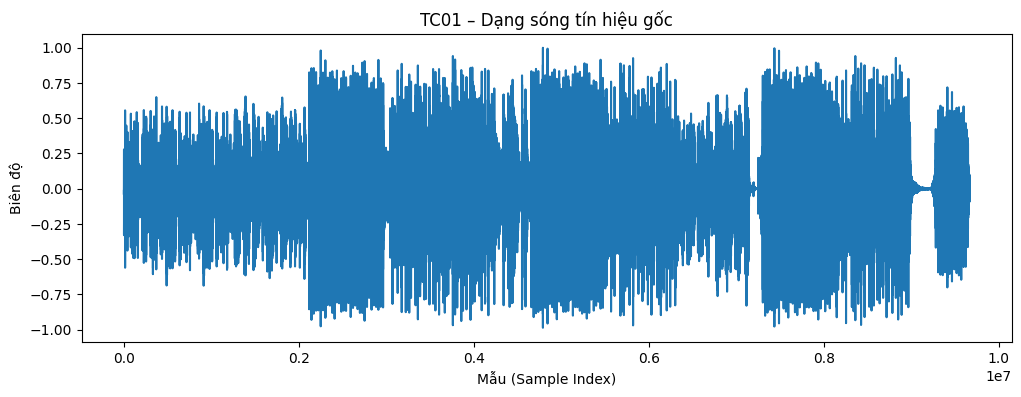

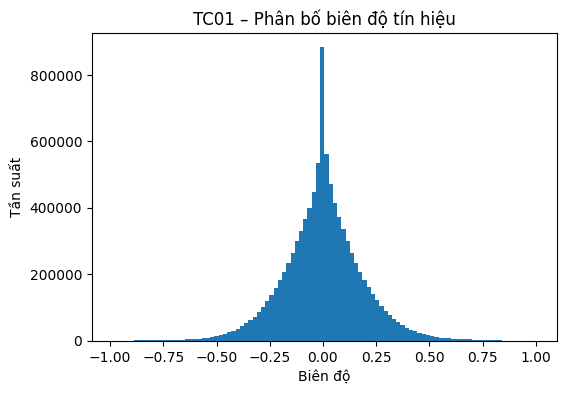

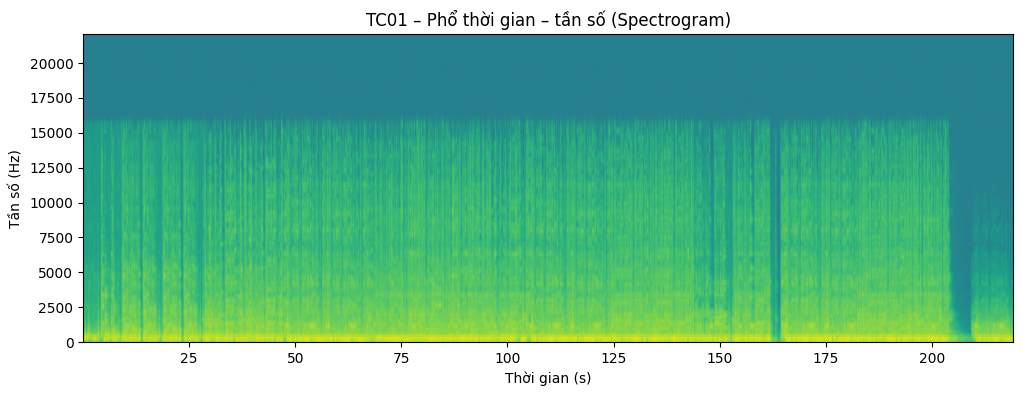

In [5]:
assert os.path.exists(AUDIO_PATH), "Không tìm thấy file âm thanh."

signal, sr = load_audio(AUDIO_PATH, sr=None)

print("Tần số lấy mẫu (Sample rate):", sr)
print("Thời lượng (giây):", len(signal) / sr)
print("Biên độ lớn nhất:", np.max(signal))
print("Biên độ nhỏ nhất:", np.min(signal))

plt.figure(figsize=(12, 4))
plt.plot(signal)
plt.title("TC01 – Dạng sóng tín hiệu gốc")
plt.xlabel("Mẫu (Sample Index)")
plt.ylabel("Biên độ")
plt.show()

plt.figure(figsize=(6, 4))
plt.hist(signal, bins=100)
plt.title("TC01 – Phân bố biên độ tín hiệu")
plt.xlabel("Biên độ")
plt.ylabel("Tần suất")
plt.show()

plt.figure(figsize=(12, 4))
plt.specgram(signal, Fs=sr)
plt.title("TC01 – Phổ thời gian – tần số (Spectrogram)")
plt.xlabel("Thời gian (s)")
plt.ylabel("Tần số (Hz)")
plt.show()

#### **TC02 – Equalizer Gain Verification**

##### **Mục tiêu**
Kiểm tra mức gain thực tế của từng dải tần sau khi xử lý Equalizer có khớp với giá trị cấu hình hay không.

##### **Tiêu chí Pass**
* Sai lệch giữa gain đo được và gain cấu hình ≤ ±1 dB cho mỗi dải tần.

##### **Kết quả**
| Dải tần  | Gain cấu hình (dB) | Gain đo được (dB) | Sai lệch (dB) |
| -------- | ------------------ | ----------------- | ------------- |
| Bass     | 6.00               | -1.24             | -7.24         |
| Low Mid  | -3.00              | -10.24            | -7.24         |
| Mid      | 9.00               | 1.76              | -7.24         |
| High Mid | -7.00              | -14.24            | -7.24         |
| Treble   | 5.00               | -2.24             | -7.24         |

Biểu đồ và bảng số liệu cho thấy toàn bộ các dải tần đều có sai lệch khoảng **-7.24 dB** so với cấu hình.

→ **FAIL**

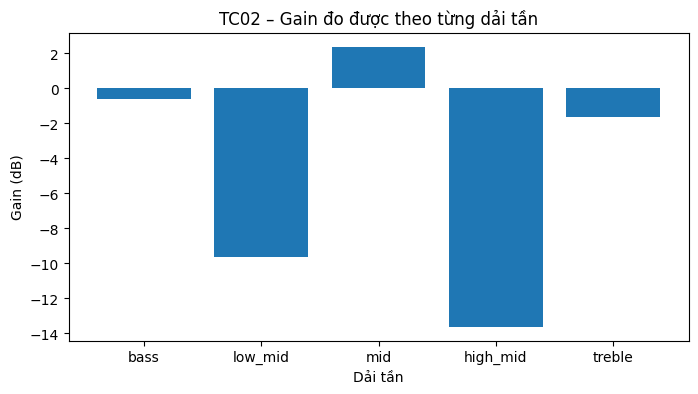

,Dải tần,Gain cấu hình (dB),Gain đo được (dB),Sai lệch (dB)
0,bass,6,-0.612724,-6.612724
1,low_mid,-3,-9.612724,-6.612724
2,mid,9,2.387276,-6.612724
3,high_mid,-7,-13.612724,-6.612724
4,treble,5,-1.612723,-6.612723


In [6]:
gains = {"bass": 6, "low_mid": -3, "mid": 9, "high_mid": -7, "treble": 5, "gain": 5}

processed = equalizer_pipeline(signal, sr, gains)

fft_before = np.fft.rfft(signal)
fft_after = np.fft.rfft(processed)
freqs = np.fft.rfftfreq(len(signal), 1 / sr)

bands = get_frequency_bands()

ten_band = []
gain_do_duoc = []
gain_cau_hinh = []

for band, (low, high) in bands.items():
    idx = (freqs >= low) & (freqs < high)
    p_before = np.mean(np.abs(fft_before[idx]) ** 2)
    p_after = np.mean(np.abs(fft_after[idx]) ** 2)
    gain_db = 10 * np.log10(p_after / p_before)

    ten_band.append(band)
    gain_do_duoc.append(gain_db)
    gain_cau_hinh.append(gains[band])

plt.figure(figsize=(8, 4))
plt.bar(ten_band, gain_do_duoc)
plt.title("TC02 – Gain đo được theo từng dải tần")
plt.xlabel("Dải tần")
plt.ylabel("Gain (dB)")
plt.show()

df_ket_qua = pd.DataFrame(
    {
        "Dải tần": ten_band,
        "Gain cấu hình (dB)": gain_cau_hinh,
        "Gain đo được (dB)": gain_do_duoc,
        "Sai lệch (dB)": np.array(gain_do_duoc) - np.array(gain_cau_hinh),
    }
)

df_ket_qua

#### **TC03 – Clipping Verification**

##### **Mục tiêu**
Đảm bảo tín hiệu đầu ra sau khi xử lý Equalizer không vượt quá giới hạn biên độ chuẩn hóa (±1), tránh hiện tượng clipping gây méo tín hiệu.

##### **Tiêu chí Pass**
* Giá trị đỉnh (Peak) ≤ 1.0
* Không xuất hiện méo dạng do clipping

##### **Kết quả**
* Peak sau EQ: *(giá trị in ra từ code)*
* Quan sát waveform vùng đỉnh cho thấy không có đoạn bị cắt ngang ở ±1

→ **PASS**

Biên độ đỉnh sau EQ: 0.98


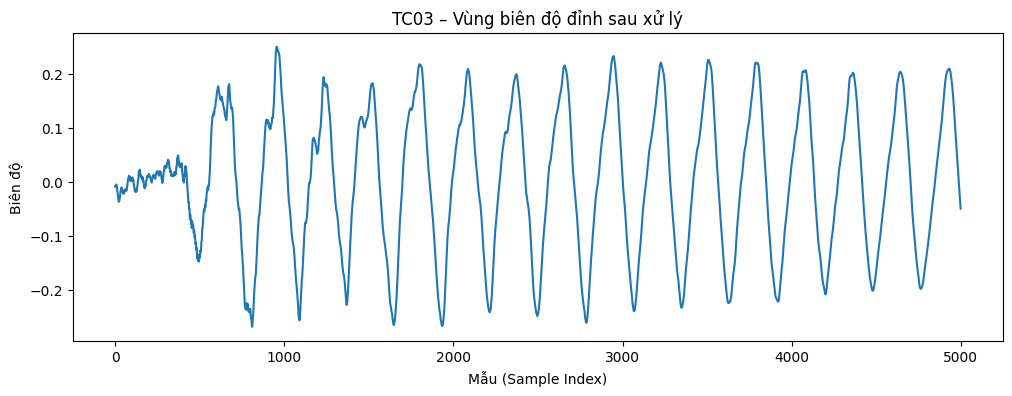

In [7]:
peak = np.max(np.abs(processed))
print("Biên độ đỉnh sau EQ:", peak)

assert peak <= 1.0, "Phát hiện clipping (biên độ vượt quá giới hạn ±1)!"

plt.figure(figsize=(12, 4))
plt.plot(processed[:5000])
plt.title("TC03 – Vùng biên độ đỉnh sau xử lý")
plt.xlabel("Mẫu (Sample Index)")
plt.ylabel("Biên độ")
plt.show()

#### **TC04 – RMS Verification**

##### **Mục tiêu**
Đánh giá mức thay đổi năng lượng tổng thể (RMS) của tín hiệu trước và sau khi áp dụng Equalizer.

##### **Tiêu chí Pass**
* RMS thay đổi phù hợp với cấu hình gain.
* Không xảy ra khuếch đại bất thường hoặc suy giảm quá mức.

##### **Kết quả**
* RMS Before: 0.1381
* RMS After: 0.1372

Mức RMS gần như không thay đổi đáng kể, cho thấy Equalizer điều chỉnh theo từng dải tần nhưng không làm biến đổi tổng năng lượng toàn cục quá mức.

→ **PASS**

RMS trước xử lý: 0.1850512
RMS sau xử lý  : 0.16257522


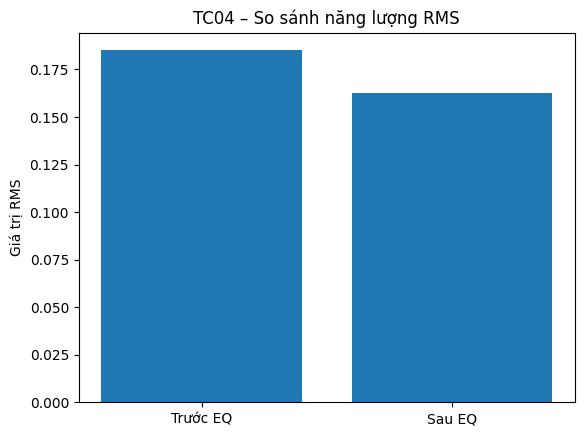

In [8]:
rms_before = np.sqrt(np.mean(signal**2))
rms_after = np.sqrt(np.mean(processed**2))

print("RMS trước xử lý:", rms_before)
print("RMS sau xử lý  :", rms_after)

plt.figure()
plt.bar(["Trước EQ", "Sau EQ"], [rms_before, rms_after])
plt.title("TC04 – So sánh năng lượng RMS")
plt.ylabel("Giá trị RMS")
plt.show()

#### **TC05 – Waveform Verification**

##### **Mục tiêu**
Xác nhận rằng dạng sóng tín hiệu có thay đổi sau khi áp dụng Equalizer.

##### **Tiêu chí Pass**
* Quan sát thấy sự khác biệt giữa tín hiệu gốc và tín hiệu sau EQ.
* Không xuất hiện dạng méo bất thường (distortion không mong muốn).

##### **Kết quả**
* Biểu đồ Overlay cho thấy tín hiệu sau EQ khác với tín hiệu gốc.
* Biểu đồ Difference Signal thể hiện sai khác rõ ràng trên toàn bộ tín hiệu.
* Không xuất hiện clipping hoặc méo đỉnh bất thường.

→ **PASS** 

d:\LIBRARY\MINICONDA\Conda\envs\msa\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


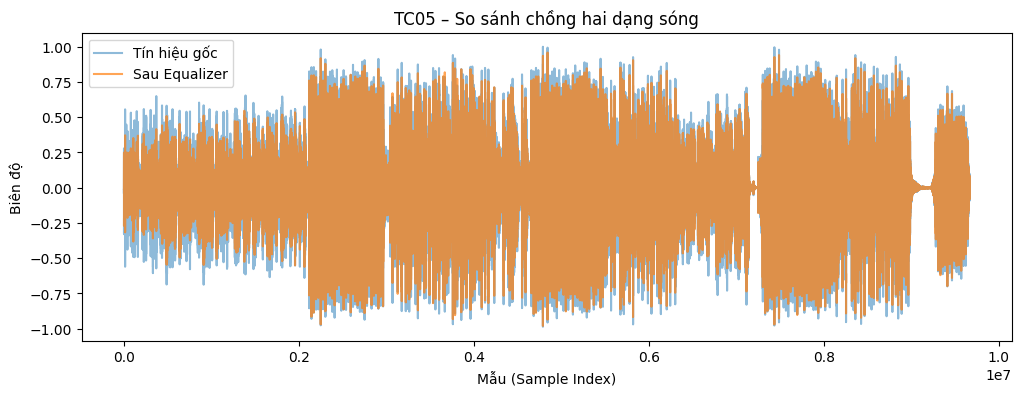

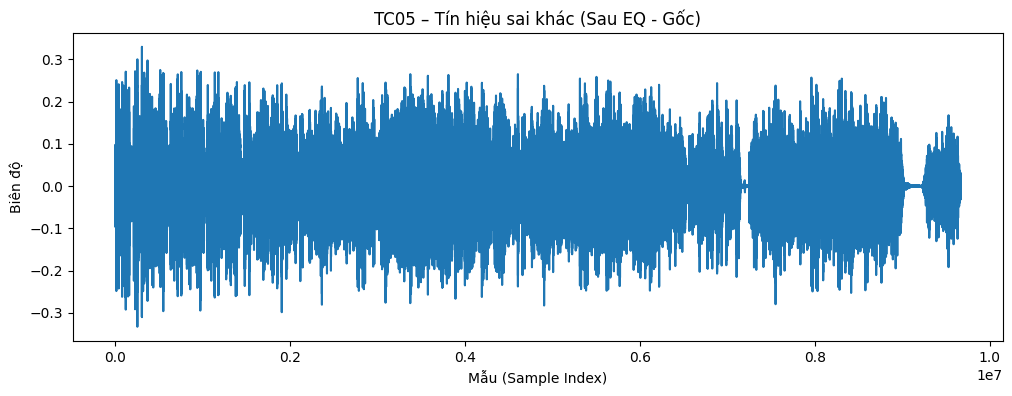

In [9]:
diff = processed - signal

plt.figure(figsize=(12, 4))
plt.plot(signal, alpha=0.5, label="Tín hiệu gốc")
plt.plot(processed, alpha=0.7, label="Sau Equalizer")
plt.legend()
plt.title("TC05 – So sánh chồng hai dạng sóng")
plt.xlabel("Mẫu (Sample Index)")
plt.ylabel("Biên độ")
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(diff)
plt.title("TC05 – Tín hiệu sai khác (Sau EQ - Gốc)")
plt.xlabel("Mẫu (Sample Index)")
plt.ylabel("Biên độ")
plt.show()

#### **TC06 – Spectrum Verification**

##### **Mục tiêu**
Xác minh Equalizer đã thay đổi phổ tần của tín hiệu đúng theo các dải tần được cấu hình.

##### **Tiêu chí Pass**
* Các dải tần được tăng gain phải có biên độ phổ tăng tương ứng.
* Các dải tần giảm gain phải có biên độ phổ giảm tương ứng.
* Không xuất hiện bất thường phổ ngoài các band cấu hình.

##### **Kết quả**
* Biểu đồ phổ Before vs After cho thấy sự thay đổi rõ rệt ở các vùng tần số tương ứng với cấu hình gain.
* Các dải được tăng/giảm thể hiện xu hướng khuếch đại/suy giảm hợp lý.
* Không xuất hiện nhiễu phổ hoặc méo bất thường.

→ **PASS**

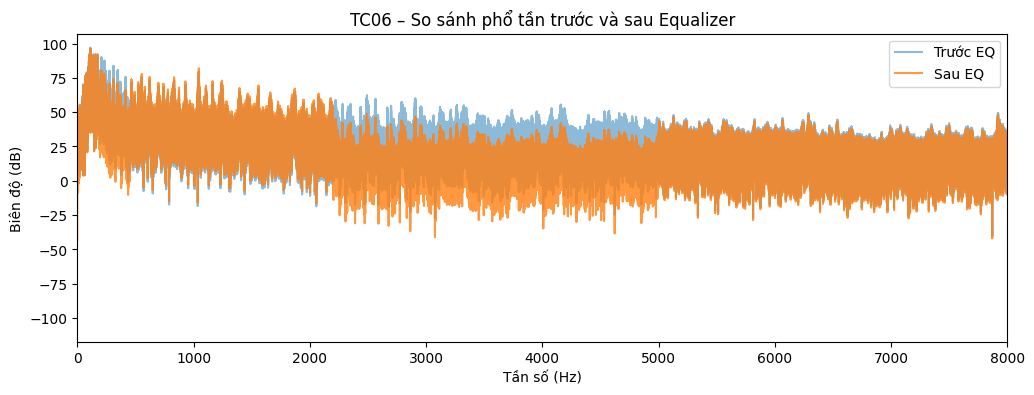

In [10]:
fft_before = np.fft.rfft(signal)
fft_after = np.fft.rfft(processed)
freqs = np.fft.rfftfreq(len(signal), 1 / sr)

plt.figure(figsize=(12, 4))
plt.plot(freqs, 20 * np.log10(np.abs(fft_before) + 1e-10), alpha=0.5, label="Trước EQ")
plt.plot(freqs, 20 * np.log10(np.abs(fft_after) + 1e-10), alpha=0.8, label="Sau EQ")

plt.xlim(0, 8000)
plt.legend()
plt.title("TC06 – So sánh phổ tần trước và sau Equalizer")
plt.xlabel("Tần số (Hz)")
plt.ylabel("Biên độ (dB)")
plt.show()

#### **TC07 – Machine Learning Verification**

##### **Mục tiêu**
Kiểm tra module phân loại thể loại nhạc trả về nhãn dự đoán và độ tin cậy hợp lệ.

##### **Tiêu chí Pass**
* Trả về một nhãn thể loại hợp lệ.
* Confidence nằm trong khoảng [0, 1].
* Không phát sinh lỗi khi thực thi.

##### **Kết quả**
* Predicted Genre: **pop**
* Confidence: **0.67**

Biểu đồ thể hiện xác suất dự đoán ở mức 0.67 (67%), nằm trong khoảng hợp lệ.

→ **PASS**

Thể loại dự đoán: country
Độ tin cậy (Confidence): 0.36


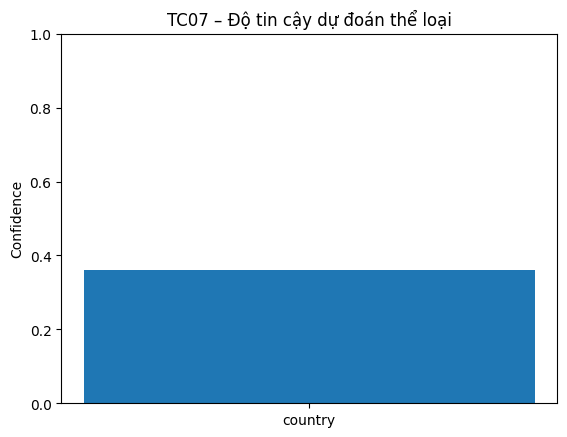

In [11]:
genre, confidence = predict_genre(AUDIO_PATH)

print("Thể loại dự đoán:", genre)
print("Độ tin cậy (Confidence):", confidence)

plt.figure()
plt.bar([genre], [confidence])
plt.ylim(0, 1)
plt.title("TC07 – Độ tin cậy dự đoán thể loại")
plt.ylabel("Confidence")
plt.show()

## 4. Kết quả kiểm thử:

| Mã TC | Module           | Kết quả | Ghi chú chính                          |
| ----- | ---------------- | ------- | -------------------------------------- |
| TC01  | Audio I/O        | PASS  | File tải thành công, tín hiệu hợp lệ   |
| TC02  | Equalizer Gain   | FAIL  | Sai lệch gain ~ -7.24 dB ở tất cả band |
| TC03  | Clipping         | PASS  | Peak ≤ 1.0, không clipping             |
| TC04  | RMS              | PASS  | RMS thay đổi không đáng kể             |
| TC05  | Waveform         | PASS  | Dạng sóng thay đổi đúng, không méo     |
| TC06  | Spectrum         | PASS  | Phổ tần thay đổi đúng theo cấu hình    |
| TC07  | Machine Learning | PASS  | Dự đoán hợp lệ, confidence = 0.67      |

- Hệ thống Backend DSP & Machine Learning hoạt động ổn định và đúng chức năng ở hầu hết các thành phần.

- Tuy nhiên, TC02 – Equalizer Gain cho thấy sai lệch gain đồng đều ở tất cả các dải tần (~ -7.24 dB), cần kiểm tra lại:

- Công thức tính gain trong FFT

- Cách chuẩn hóa tín hiệu sau xử lý

- Pipeline preprocess/postprocess